# ПЗ-8. Автоматическое дифференцирование: дуалы, ленты и настоящие градиенты
### (репетиция Лекции 8 — прямой режим, обратный режим, JVP/VJP, PyTorch)

> 🎮 **Сюжет семинара.** Разности (Л6) платят точностью, комплексный
> шаг (Л7) — аналитичностью и прогонами. Автодифференцирование берёт
> **код как есть** и выносит из него градиент с точностью до машинного
> эпсилон за цену нескольких проходов. Сегодня мы соберём оба режима
> руками и погоняем настоящий `autograd` на живых задачах.

| уровень | метка | что это значит |
|---|---|---|
| 🟢 | прогрев | успеваем до кофе |
| 🟠 | продвинутая | нужна голова |
| ★ | звёздочка | бонус после основной линии |
| ★★ | двойная звёздочка | финальный вызов |

**Как работать.** Постановки — в md-блоках, решаете — в ячейках
`✍️ ДЕЛАЙТЕ`. Проверка `✅` исполняется без ошибок только при
верном решении. Идите сверху вниз. На задачах 1 и 4–8 пригодится
`torch`; задачи 2–3 — чистый Python без torch.

In [ ]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch
plt.rcParams['figure.dpi'] = 110
torch.manual_seed(0)
print('numpy', np.__version__, '| torch', torch.__version__)

numpy 1.26.4 | torch 2.11.0+cpu


## 📋 Шпаргалка

**AD за пять строк.** Программа = граф примитивов с локальными
производными. Прямой режим тащит **касательные**
$\tilde v_i = \sum_j \frac{\partial\varphi_i}{\partial v_j}\tilde v_{i_j}$
(на выходе — столбец якобиана $J\,e_j$); обратный — **сопряжённые**
$\bar v_j \,{+}{=}\, \bar v_i\,\frac{\partial v_i}{\partial v_j}$
от seed $\bar y = 1$ (на выходе — строка $u^{\top}J$).

| инструмент | что делает | где |
|---|---|---|
| дуальные числа $a + b\,\varepsilon$, $\varepsilon^2 = 0$ | прямой режим одной оценкой: `val, dval` | Задача 2 |
| лента + `+=` накопление | обратный режим одним backward | Задача 3 |
| `torch.autograd.grad / backward` | обратный режим на тензорах | Задачи 1, 4, 7 |
| `torch.func.jvp` / `torch.func.vjp` | JVP и VJP с seed-вектором | Задача 5 |
| `torch.func.jacfwd` / `jacrev` | полный якобиан прямым/обратным | Задача 6 |
| `torch.utils.checkpoint` | память $O(\sqrt L)$ ценой +1 forward | Задача 8 |

**Сложность (Баура–Штрассен, 1983).** Градиент любой арифметической
программы за $\sim\!2$–$3$ прохода той же программы (по времени),
но прямой режим платит прогонами на **направление** ($n$ штук),
а обратный — памятью на **ленту** ($O(L)$).

**Честность.** AD дифференцирует реализацию: негладкие точки
(`relu`, `abs`, `max`) получают конвенциональное значение
(gradcheck никогда не сойдётся там, где производной нет);
устойчивость формул яснее проверять до дифференцирования.

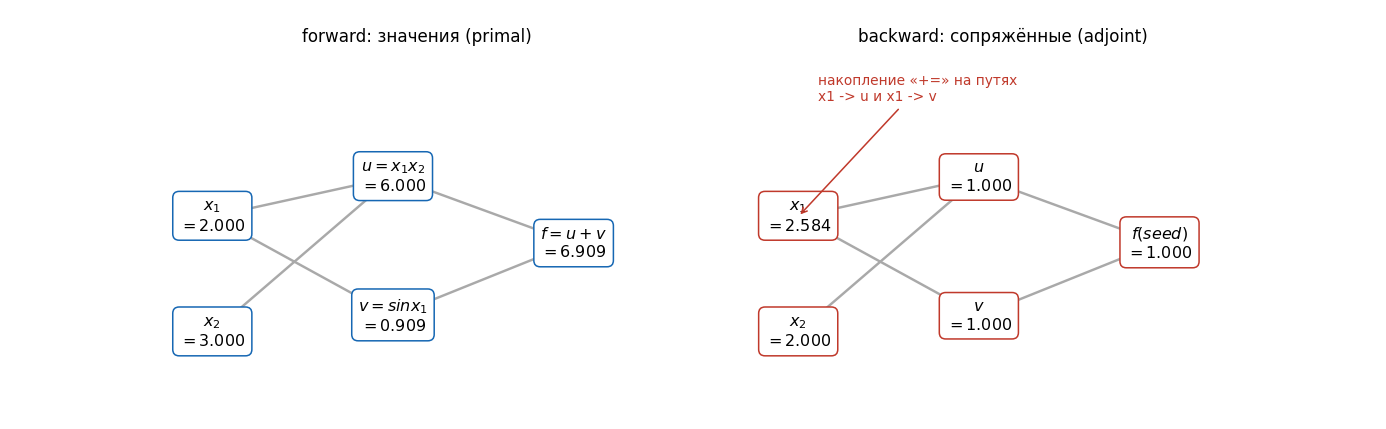

In [ ]:
# Карта примера Лекции 8: f = x1*x2 + sin(x1) — значения вперёд, сопряжённые назад
fig, axes = plt.subplots(1, 2, figsize=(12.6, 3.9))
POS = {"x1": (0.08, 0.5), "x2": (0.08, 0.15), "u": (0.45, 0.62),
       "v": (0.45, 0.2), "f": (0.82, 0.42)}
EDGES = [("x1", "u"), ("x2", "u"), ("x1", "v"), ("u", "f"), ("v", "f")]
NODES_F = [("x1", "x_1", 2.0), ("x2", "x_2", 3.0), ("u", "u = x_1 x_2", 6.0),
           ("v", "v = sin x_1", np.sin(2.0)), ("f", "f = u + v", 6.0 + np.sin(2.0))]
NODES_B = [("x1", "x_1", 3.0 + np.cos(2.0)), ("x2", "x_2", 2.0),
           ("u", "u", 1.0), ("v", "v", 1.0), ("f", "f (seed)", 1.0)]
for ax, nodes, ttl, col in [(axes[0], NODES_F, "forward: значения (primal)", "#1667b3"),
                            (axes[1], NODES_B, "backward: сопряжённые (adjoint)", "#c0392b")]:
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    for a, b in EDGES:
        # в forward стрелка идёт от входа к выходу, в backward — наоборот
        tail, head = (POS[a], POS[b]) if ttl.startswith("forward") else (POS[b], POS[a])
        ax.annotate('', xy=head, xytext=tail,
                    arrowprops=dict(arrowstyle='->', color='darkgray', lw=1.6))
    for nid, label, val in nodes:
        px, py = POS[nid]
        ax.text(px, py, f"${label}$\n$= {val:.3f}$", ha="center", va="center",
                fontsize=10.5, bbox=dict(boxstyle="round,pad=0.4",
                                         fc="white", ec=col))
    ax.set_title(ttl, fontsize=11)
axes[1].annotate("накопление «+=» на путях\nx1 -> u и x1 -> v",
                 xy=(0.08, 0.5), xytext=(0.12, 0.85),
                 arrowprops=dict(arrowstyle="->", color="#c0392b"),
                 fontsize=9, color="#c0392b")
plt.show()

---
## 🟢 Задача 1. Первый градиент: ноль шагов $h$

$$f(x) = \sin x + x^{2}, \qquad x_0 = 1.$$

**Что сделать:**

- **(а)** Вычислить $f'(x_0)$ через `loss.backward()` и собрать `G1`
  (значение — `x.grad[0].item()`). Двойная точность обязана!
- **(б)** Не обнуляя `x.grad`, построить и прогнать потерю ещё раз —
  собрать `G2`. Объяснить печатной строкой, что произошло
  (накопление «${+}{=}$» в узле `AccumulateGrad`).
- **(в)** Обнулить (`x.grad = None` — то же, что `optimizer.zero_grad()`)
  и собрать `G3`. Сверить все три с аналитикой $\cos 1 + 2$.

> 💡 Порядок в Лекции 8, §8: `.grad` пишется у листьев; повторный
> `backward()` строит граф заново и **прибавляет**.

In [ ]:
# Скаффолд задачи 1: функция и точное значение
FP = lambda xt: torch.sin(xt) + xt ** 2
G_EXACT = float(np.cos(1.0) + 2.0)
print(f"f = sin(x) + x^2,  x0 = 1,  точная f' = cos(1) + 2 = {G_EXACT:.12f}")
print("контракты: G1 — после 1-го backward; G2 — после 2-го БЕЗ обнуления;")
print("           G3 — после zero_grad и 3-го backward. Все — числа типа float")

f = sin(x) + x^2,  x0 = 1,  точная f' = cos(1) + 2 = 2.540302305868
контракты: G1 — после 1-го backward; G2 — после 2-го БЕЗ обнуления;
           G3 — после zero_grad и 3-го backward. Все — числа типа float


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 1
# TODO (а): G1 — производная одним backward (double!)
# TODO (б): G2 — второй backward без обнуления + строка-объяснение (print)
# TODO (в): G3 — zero_grad + третий backward


In [ ]:
# ✅ Самопроверка задачи 1
import numpy as np
assert abs(G1 - G_EXACT) < 1e-9, f"G1 обязан совпасть с аналитикой: {G1!r}"
assert abs(G2 - 2 * G_EXACT) < 1e-9, (f"G2 = накопленные градиенты: "
                                      f"{G2!r} ≠ 2×({G_EXACT:.6f})")
assert abs(G3 - G_EXACT) < 1e-9, f"G3 после обнуления обязан совпасть: {G3!r}"
print(f"✅ Задача 1 ок: G1 = {G1:.12f}; G2 = {G2:.12f} (накопление «+=»); "
      f"G3 = {G3:.12f}")

---
## 🟢 Задача 2. Дуальное кольцо: допишите операции

В скаффолде — класс `Dual` из Лекции 8 с готовыми `+`, `*` и
образцом `__sub__`. Кольцо $\mathbb{R}[\varepsilon]/\varepsilon^{2}$:
ряд Тейлора обрывается сам, касательная выходит **точной** — без $h$.

Правила сложных функций:

$$d\_exp(u) = e^{u_{\text{val}}}\,(u_{\text{val}},\, u_{\text{dval}}),
\qquad d\_\tanh(u) = \operatorname{sech}^2(u_{\text{val}})\cdot u_{\text{dval}},$$

$$x^p:\ \ (x^p)' = p\,x^{p-1},\qquad
\dfrac{a}{b}:\quad \tilde{c} = \dfrac{\tilde a\,b - a\,\tilde b}{b^{2}}.$$

**Что сделать:**

- **(а)** Дописать `__truediv__`, `__pow__`, `d_exp`, `d_tanh`.
- **(б)** Реализовать три функции (аргумент — `Dual`):

$$g_1(x) = \dfrac{x^{2} + 1}{x + 2}, \qquad
g_2(x) = x\,e^{x}\,\tanh x, \qquad
g_3(x) = (\tanh x + 2)^{3}.$$

- **(в)** Прогнать от `Dual(x0, 1.0)` при $x_0 = 1.1,\ 0.7,\ 0.5$
  соответственно; напечатать `val`/`dval` — против точной формулы
  и центральной разности.

In [ ]:
# Скаффолд задачи 2: Dual c готовой арифметикой
import math

class Dual:
    # дуальное число: значение + касательная
    def __init__(self, val, dval=0.0):
        self.val, self.dval = val, dval
    def __add__(self, o):
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.val + o.val, self.dval + o.dval)
    __radd__ = __add__
    def __mul__(self, o):
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.val * o.val, self.val * o.dval + o.val * self.dval)
    __rmul__ = __mul__
    def __sub__(self, o):          # вычитание — образец готовой операции
        o = o if isinstance(o, Dual) else Dual(o)
        return Dual(self.val - o.val, self.dval - o.dval)
    # ↓ TODO (а): __truediv__, __pow__, d_exp(u), d_tanh(u)

X0G1, X0G2, X0G3 = 1.1, 0.7, 0.5
print("контракты: g1(x: Dual) -> Dual, g2, g3")
print(f"x0: g1 при {X0G1}, g2 при {X0G2}, g3 при {X0G3}")
print("прогон: Dual(x0, 1.0) -> y.val (значение), y.dval (производная)")

контракты: g1(x: Dual) -> Dual, g2, g3
x0: g1 при 1.1, g2 при 0.7, g3 при 0.5
прогон: Dual(x0, 1.0) -> y.val (значение), y.dval (производная)


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 2
# TODO (а): __truediv__, __pow__ (методы внутри класса), d_exp, d_tanh (функции)
# TODO (б): g1, g2, g3 — функции от Dual
# TODO (в): прогон и печать val/dval против точных значений


In [ ]:
# ✅ Самопроверка задачи 2
import numpy as np
import math
import sympy as sp
XS = sp.symbols('x')
REGS = [(g1, X0G1, (XS**2 + 1) / (XS + 2)),
        (g2, X0G2, XS * sp.exp(XS) * sp.tanh(XS)),
        (g3, X0G3, (sp.tanh(XS) + 2) ** 3)]
for i, (gfn, x0, ex) in enumerate(REGS, 1):
    y = gfn(Dual(x0, 1.0))
    ev = float(ex.subs(XS, x0))
    ed = float(sp.diff(ex, XS).subs(XS, x0))
    h = 1e-5
    realk = lambda t: float(ex.subs(XS, t))
    cd = (realk(x0 + h) - realk(x0 - h)) / (2 * h)
    assert abs(y.val - ev) < 1e-10, f"g{i}.val: {y.val!r} vs {ev!r}"
    assert abs(y.dval - ed) < 1e-10, f"g{i}.dval: {y.dval!r} vs {ed!r}"
    assert abs(cd - ed) < 1e-6, f"g{i}: движок сам не согласован ({cd!r})"
print("✅ Задача 2 ок: дуальное кольцо согласуется с sympy на g1/g2/g3")

---
## 🟠 Задача 3. Лента своими руками: допишите `Var` и посчитайте $\nabla g$

В скаффолде — класс `Var` из Лекции 8: `+`, `*`, `sin`, `backward`
(топологический обход + накопление «${+}{=}$»). Допишите `__sub__`,
`exp` и `log` — и донастройте их на «живую» цель:

$$g(x, y) = x\,y\,e^{\,x-y} + \ln\!\bigl(x^{2} + y^{2} + 1\bigr).$$

Правила (от себя, на бумаге): $\dfrac{d}{dz}e^{z} = e^{z}$,
$\dfrac{d}{dz}\ln z = \dfrac{1}{z}.$

**Что сделать:**

- **(а)** Дописать `__sub__` (и `__rsub__` по желанию), `exp()`, `log()`.
- **(б)** Реализовать `grad_g(xa, ya)` — строит `Var(xa)`, `Var(ya)`,
  пересчитывает $g$, зовёт `backward()` и возвращает пару
  `(x.grad, y.grad)` (float).
- **(в)** Сверить результат со стандартными центральными разностями
  (печать) в точках $(1.3, -0.2)$ и $(-0.5, 0.7)$. Обратный режим
  даёт **оба** частных производных за один backward — так и печать
  сделайте.

In [ ]:
# Скаффолд задачи 3: Var с готовыми +, *, sin, backward
import math

class Var:
    # узел графа: значение + parents (узел, локальная производная) + grad
    def __init__(self, val, parents=()):
        self.val, self.parents, self.grad = val, parents, 0.0
    def __add__(self, o):
        o = o if isinstance(o, Var) else Var(o)
        return Var(self.val + o.val, ((self, 1.0), (o, 1.0)))
    def __mul__(self, o):
        o = o if isinstance(o, Var) else Var(o)
        return Var(self.val * o.val, ((self, o.val), (o, self.val)))
    def sin(self):
        return Var(math.sin(self.val), ((self, math.cos(self.val)),))
    # ↓ TODO (а): __sub__ (+ __rsub__ по желанию), exp(), log()

    def backward(self):
        # топологический порядок обхода (без рекурсии)
        order, seen = [], set()
        stack = [(self, False)]
        while stack:
            node, done = stack.pop()
            if done:
                order.append(node); continue
            if id(node) in seen:
                continue
            seen.add(id(node))
            stack.append((node, True))
            for parent, _ in node.parents:
                if id(parent) not in seen:
                    stack.append((parent, False))
        self.grad = 1.0                    # seed: сопряжённого_выхода = 1
        for node in reversed(order):       # от выхода к входам
            for parent, local in node.parents:
                parent.grad += local * node.grad    # «+=»: накапливаем!

print("контракт: grad_g(xa, ya) -> (grad_x, grad_y)")
print("проверка отладкой: g(1.3, -0.2) считается и x.grad/y.grad заполняются")

контракт: grad_g(xa, ya) -> (grad_x, grad_y)
проверка отладкой: g(1.3, -0.2) считается и x.grad/y.grad заполняются


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 3
# TODO (а): __sub__, exp(), log() внутри класса Var
# TODO (б): def grad_g(xa, ya): ... -> (x.grad, y.grad)
# TODO (в): сверка с центральными разностями в двух точках (печать)


In [ ]:
# ✅ Самопроверка задачи 3
import numpy as np
import math
def g_real(u, w):
    return u * w * math.exp(u - w) + math.log(u * u + w * w + 1.0)
def central(u, w, h=1e-5):
    gx = (g_real(u + h, w) - g_real(u - h, w)) / (2 * h)
    gy = (g_real(u, w + h) - g_real(u, w - h)) / (2 * h)
    return gx, gy
for (xa, ya) in [(1.3, -0.2), (-0.5, 0.7)]:
    gx, gy = grad_g(xa, ya)
    cx, cy = central(xa, ya)
    assert abs(gx - cx) < 1e-8, f"grad_x({xa},{ya}): {gx!r} vs {cx!r}"
    assert abs(gy - cy) < 1e-8, f"grad_y({xa},{ya}): {gy!r} vs {cy!r}"
print("✅ Задача 3 ок: лента выдаёт полный grad g за один backward")

---
## 🟠 Задача 4. Химмельблау: настоящий спуск на настоящем движке

Классический полицентрический полином — четыре минимума сразу:

$$f(x, y) = \bigl(x^{2} + y - 11\bigr)^{2} + \bigl(x + y^{2} - 7\bigr)^{2},$$

$$\text{корни } \nabla f \approx\ (3,\ 2), \ (-2.805,\ 3.131),\
(-3.779,\ -3.283),\ (3.584,\ -1.848).$$

**Что сделать:**

- **(а)** Из четырёх стартов скаффолда (`STARTS`) спуститься Adam'ом
  (lr = 0.05, 2000 шагов): в цикле `opt.zero_grad()` →
  `F_H(p).backward()` → `opt.step()`; результат — список `PTS`
  (четыре массива длины 2).
- **(б)** Таблица: старт, финальная точка, расстояние до ближайшего
  известного корня, $|\nabla f|$ там.
- **(в)** Контурный график: уровни $f$, старты и траектории спуска.
  Почему у Adam'а нет шага $h$ «под потолок» (ср. $U$-кривая Л6)?
  — печатная рефлексия.

> 🧠 Движок сам ведёт ленту: `backward()` ставит seed $=1$ на выход
> $f$ и разматывает сопряжённые — итог в `p.grad`.

известные минимумы:
 [[ 3.        2.      ]
 [-2.805118  3.131312]
 [-3.77931  -3.283186]
 [ 3.584428 -1.848126]]
старты: [(0.0, 0.0), (-3.0, 3.0), (-4.0, -3.5), (4.0, -2.0)] | adam: lr = 0.05, шагов = 2000
контракт: PTS — список из 4 точек-итогов (любой array-like длины 2)


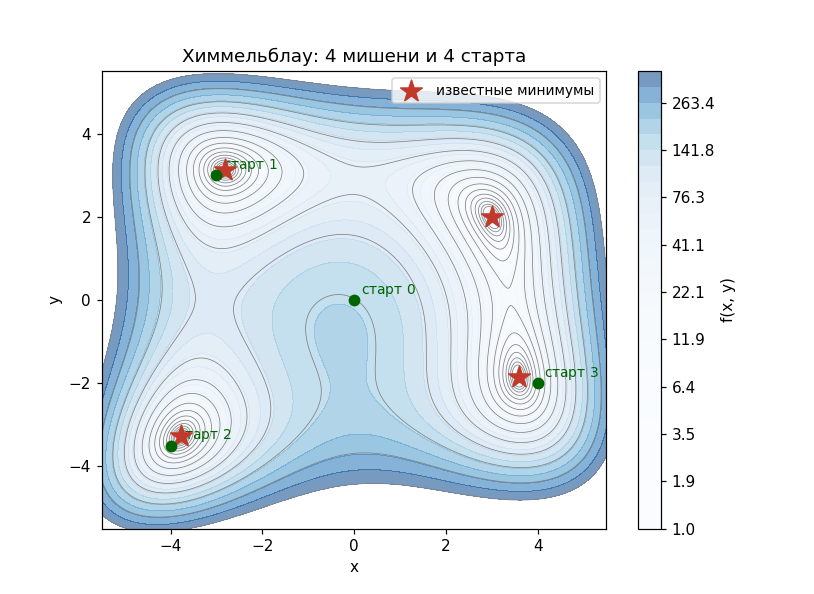

In [ ]:
# Скаффолд задачи 4: функция, известные корни, старты
F_H = lambda p: (p[0] ** 2 + p[1] - 11) ** 2 + (p[0] + p[1] ** 2 - 7) ** 2
ROOTS = np.array([[3.0, 2.0],
                  [-2.805118, 3.131312],
                  [-3.779310, -3.283186],
                  [3.584428, -1.848126]])
STARTS = [(0.0, 0.0), (-3.0, 3.0), (-4.0, -3.5), (4.0, -2.0)]
LR, STEPS = 0.05, 2000
print("известные минимумы:\n", ROOTS)
print("старты:", STARTS, "| adam:", f"lr = {LR}, шагов = {STEPS}")
print("контракт: PTS — список из 4 точек-итогов (любой array-like длины 2)")

fig, ax = plt.subplots(figsize=(7.4, 5.4))
tt = np.linspace(-5.5, 5.5, 300)
XX, YY = np.meshgrid(tt, tt)
FF = (XX ** 2 + YY - 11) ** 2 + (XX + YY ** 2 - 7) ** 2
CS = ax.contourf(XX, YY, FF, levels=np.logspace(0, 2.6, 30), cmap="Blues", alpha=0.55)
fig.colorbar(CS, ax=ax, label="f(x, y)")
ax.contour(XX, YY, FF, levels=np.logspace(0, 2.6, 15), colors="gray", linewidths=0.5)
ax.scatter(ROOTS[:, 0], ROOTS[:, 1], marker="*", s=220, color="#c0392b", zorder=6,
           label="известные минимумы")
for si, (sx, sy) in enumerate(STARTS):
    ax.scatter([sx], [sy], marker="o", s=45, color="darkgreen", zorder=6)
    ax.text(sx + 0.15, sy + 0.15, f"старт ${si}$", fontsize=9, color="darkgreen")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Химмельблау: 4 мишени и 4 старта")
ax.legend(fontsize=9)
plt.show()

In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 4
# TODO (а): PTS — 4 финальные точки (tensor->numpy), по одной на каждый старт
# TODO (б): таблица старт->финиш->ближайший корень->|grad f| (печать)
# TODO (в): контур + траектории (рисовать прямо в этой ячейке) + рефлексия


In [ ]:
# ✅ Самопроверка задачи 4
import numpy as np
import torch
PTS2 = [np.asarray(p, dtype=float).reshape(-1) for p in PTS]
assert len(PTS2) == 4, "нужны 4 финальные точки"
print(f"{'старт':>13} | {'финиш':>22} | d(ближ. корень) | |grad f|")
for k, (sx, sy) in enumerate(STARTS):
    p = PTS2[k]
    dmin = min(np.linalg.norm(p - r) for r in ROOTS)
    root = ROOTS[int(np.argmin([np.linalg.norm(p - r) for r in ROOTS]))]
    ptT = torch.tensor(p, dtype=torch.float64, requires_grad=True)
    gvT = torch.autograd.grad(F_H(ptT), ptT)[0]
    gnorm = float(np.linalg.norm(gvT.detach().numpy()))
    assert dmin < 0.05, f"сходил не в минимум: старт {sx},{sy} -> {p}, dmin {dmin:.3f}"
    assert gnorm < 5e-2, f"не докатился до дна: |grad f| = {gnorm:.3e} в точке {p}"
    print(f"({sx:+.1f},{sy:+.1f}) | ({p[0]:+10.4f},{p[1]:+10.4f}) | "
          f"{dmin:15.2e} | {gnorm:.2e}  (корень {root[0]:+.2f},{root[1]:+.2f})")
for r in ROOTS:                       # каждый корень кем-то найден
    dmins = [np.linalg.norm(p - r) for p in PTS2]
    assert min(dmins) < 0.05, f"корень {r} не найден ни одним стартом: {dmins}"
print("✅ Задача 4 ок: все 4 минимума Химмельблау найдены Adam'ом")

---
## 🟠 Задача 5. JVP против VJP: $\mathbb{R}^{2} \to \mathbb{R}^{3}$

$$f(x_1, x_2) = \bigl(\sin x_1,\ x_1 x_2,\ e^{x_1 + x_2}\bigr),
\qquad x_0 = (1.1,\ -0.4),$$

$$J = \begin{pmatrix}
\cos x_1 & 0\\ x_2 & x_1\\ e^{x_1+x_2} & e^{x_1+x_2}\end{pmatrix}(x_0),
\qquad v = (1,\ -2),\qquad u = (0.5,\ -1,\ 2).$$

**Что сделать:**

- **(а)** `JF = torch.func.jacfwd(f)(x)` и `JR = torch.func.jacrev(f)(x)`;
  напечатать и убедиться — это одна матрица ($3\times2$).
- **(б)** `JVPE = torch.func.jvp(f, (x,), (v,))`: tangent обязан
  совпасть со столбцом $Jv$.
- **(в)** `torch.func.vjp` → pullback: `VJPU = pullback(u)[0]`
  — строка $u^{\top}J$. Выбор режима для **полного** якобиана:
  прямой платит $n_{\text{вх}}$ касательными, обратный —
  $n_{\text{вых}}$ спусками; здесь $2 < 3$ — кто дешевле?
  Печать вывода.

In [ ]:
# Скаффолд задачи 5: функция R^2 -> R^3 и векторы перемножений
F_J = lambda xt: torch.stack([torch.sin(xt[0]),
                              xt[0] * xt[1],
                              torch.exp(xt[0] + xt[1])])
X_J = torch.tensor([1.1, -0.4], dtype=torch.float64)
V_J = torch.tensor([1.0, -2.0], dtype=torch.float64)
U_J = torch.tensor([0.5, -1.0, 2.0], dtype=torch.float64)
print("f = (sin x1, x1*x2, exp(x1+x2)); x0 = (1.1, -0.4)")
print("J = [[cos x1, 0], [x2, x1], [e^(x1+x2), e^(x1+x2)]]  (3 x 2)")
print(f"v = {V_J.tolist()} (столбец Jv: прямой режим), u = {U_J.tolist()} (строка u^T J: обратный)")

f = (sin x1, x1*x2, exp(x1+x2)); x0 = (1.1, -0.4)
J = [[cos x1, 0], [x2, x1], [e^(x1+x2), e^(x1+x2)]]  (3 x 2)
v = [1.0, -2.0] (столбец Jv: прямой режим), u = [0.5, -1.0, 2.0] (строка u^T J: обратный)


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 5
# TODO (а): JF, JR — якобианы обоими режимами + печать
# TODO (б): JVPE — пара (primal, tangent) из torch.func.jvp
# TODO (в): VJPU — строка через torch.func.vjp + вывод про выбор режима


In [ ]:
# ✅ Самопроверка задачи 5
import numpy as np
import torch
J_EX = torch.tensor([
    [float(np.cos(1.1)), 0.0],
    [-0.4, 1.1],
    [float(np.exp(0.7)), float(np.exp(0.7))]], dtype=torch.float64)
assert JF.shape == (3, 2) and JR.shape == (3, 2), f"формы: {JF.shape}, {JR.shape}"
assert torch.allclose(JF, J_EX, atol=1e-9), f"jacfwd != аналитика: {JF}"
assert torch.allclose(JR, J_EX, atol=1e-9), f"jacrev != аналитика: {JR}"
assert torch.allclose(JVPE[1], J_EX @ V_J, atol=1e-9), f"JVP != J @ v: {JVPE[1]}"
assert torch.allclose(VJPU, U_J @ J_EX, atol=1e-9), f"VJP != u^T @ J: {VJPU}"
print("✅ Задача 5 ок: J совпала с аналитикой; JVP тянет столбец, VJP — строку")

---
## ★ Задача 6. Размер имеет значение: `jacfwd` против `jacrev`

Якобиан линейного слоя $\mathrm{PREDICT}(x) = \tanh(x W^{\top} + b)$
по входу $x$ — формы $(D_{out}, D_{in})$. Лекция 8 обещала:
**режим выбирается по короткой стороне** — посчитаем времена.

**Что сделать:**

- **(а)** Написать `PREDICT(W, b, x)` (заметьте: слой — $x W^{\top}$).
- **(б)** Для форм $(D_{in}, D_{out}) = (32, 2048)$ и $(2048, 32)$:
  `torch.func.jacfwd / jacrev` по `argnums=2`, сверка всехclose и
  таблица времени (15 повторов, с прогревом) — прямо в этой ячейке.
- **(в)** Печатный вывод: какая форма выигрывает у какого режима
  и почему ($m \times n$: полный $J$ за $\min(m, n)$ проходов).

In [ ]:
# Скаффолд задачи 6: формы и план бенчмарка
import torch, time
SHAPES = [(32, 2048), (2048, 32)]
N_REP = 15
print("PREDICT(W, b, x) = tanh(x @ W.T + b):  W формы (Dout, Din)")
print("формы якобиана по x:", [(dout, din) for (din, dout) in SHAPES])
print(f"повторов на измерение: {N_REP}")
print("теория: полный J за min(m, n) прогонов — короткую сторону выбирает режим")

PREDICT(W, b, x) = tanh(x @ W.T + b):  W формы (Dout, Din)
формы якобиана по x: [(2048, 32), (32, 2048)]
повторов на измерение: 15
теория: полный J за min(m, n) прогонов — короткую сторону выбирает режим


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 6 (звёздочка)
# TODO (а): PREDICT(W, b, x) — тензорная функция
# TODO (б): таблица форма | время jacfwd | время jacrev | победитель (с allclose-сверкой)
# TODO (в): вывод печатными строками


In [ ]:
# ✅ Самопроверка задачи 6
import torch
torch.manual_seed(3)
for (din, dout) in SHAPES:
    Wb = torch.randn(dout, din)
    bb = torch.randn(dout)
    xb = torch.randn(din)
    j1 = torch.func.jacfwd(PREDICT, argnums=2)(Wb, bb, xb)
    j2 = torch.func.jacrev(PREDICT, argnums=2)(Wb, bb, xb)
    assert j1.shape == (dout, din), f"форма якобиана: {j1.shape}"
    assert torch.allclose(j1, j2, atol=1e-5), f"режимы расходятся при {din}->{dout}"
print("✅ Задача 6 ок: оба режима дают один якобиан на обеих формах")
print("(а сами времена — в таблице, которую вы собрали в ячейке ДЕЛАЙТЕ)")

---
## ★ Задача 7. Производная в изломе: relu в нуле

Градиент `relu` в нуле не существует математически, а движок молча
возвращает **конвенцию**: у `torch.relu` — ноль. Сравните с центральными
разностями ($h \to 0$: слева 0, справа 1 → среднее 0.5) и с односторонними.

**Что сделать:**

- **(а)** Собрать `G_RELU` — список градиентов `torch.relu` в точках
  $-0.5,\ 0,\ 0.5$ (обратный режим, double).
- **(б)** Собрать `C_RELU` — центральную разностьrelu в нуле
  ($h = 10^{-7}$); вычислить и односторонние (печать).
- **(в)** Печать вердикта: что из этого «правда», а что конвенция;
  где это может запутать численный градиентный метод.
  (Подсказка: `gradcheck` с разностями в нуле даст 0.5 — совпадёт
  с `central`, но не с конвенцией AD.)

In [ ]:
# Скаффолд задачи 7: точки и план
XS_RELU = torch.tensor([-0.5, 0.0, 0.5], dtype=torch.float64, requires_grad=True)
H_RELU = 1e-7
print("relu(z) = max(0, z);  производная: слева 0, справа 1, в нуле — не существует")
print(f"контракты: G_RELU — список из 3 чисел (autograd); C_RELU — central при h = {H_RELU:g}")

relu(z) = max(0, z);  производная: слева 0, справа 1, в нуле — не существует
контракты: G_RELU — список из 3 чисел (autograd); C_RELU — central при h = 1e-07


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 7 (звёздочка)
# TODO (а): G_RELU — grad torch.relu в трёх точках (backward)
# TODO (б): C_RELU — central в нуле; односторонние разности — печатью
# TODO (в): вердикт печатными строками


In [ ]:
# ✅ Самопроверка задачи 7
import numpy as np
assert len(G_RELU) == 3, f"нужно 3 градиента: {G_RELU!r}"
assert G_RELU[0] == 0.0, f"слева от нуля grad обязателен 0: {G_RELU[0]!r}"
assert G_RELU[1] == 0.0, f"в нуле torch выбирает конвенцию 0: {G_RELU[1]!r}"
assert abs(G_RELU[2] - 1.0) < 1e-12, f"справа grad обязателен 1: {G_RELU[2]!r}"
assert abs(C_RELU - 0.5) < 1e-12, f"central в нуле обязан дать 0.5: {C_RELU!r}"
print(f"✅ Задача 7 ок: autograd {G_RELU} (конвенция 0), central = {C_RELU} (осреднённое)")
print("математика и конвенция: производной в нуле нет — AD даёт 0 по соглашению; gradcheck тут хромает и это честно")

---
## ★★ Задача 8. Финальный вызов: чекпоинтинг — платим временем за память

Цепочка из 30 блоков $h_{k+1} = \tanh(h_k)\,h_k + \sin^2(h_k)$ от
одного входа $x \in \mathbb{R}^{64}$. Лента хранит **все**
промежуточные значения; `torch.utils.checkpoint` сохраняет только
входы и пересчитывает блоки при backward.

**Что сделать:**

- **(а)** Собрать цепочку; прогнать меру (в скаффолде уже готова —
  меряет через `saved_tensors_hooks`) **без** чекпоинта и **с** ним
  (каждый блок обёрнут в `checkpoint(..., use_reentrant=False)`);
  сохранить `N1, E1, C1` и `N2, E2, C2`
  и градиенты `GRAD_NC`, `GRAD_CP`.
- **(б)** Таблица: тензоров сохранено / элементов / вызовов блока /
  погрешность градиентов между вариантами.
- **(в)** Печать вердикта: во сколько раз сократилась лента и сколько
  стоит пересчёт. Память $O(\sqrt L)$ (Гриванк) против полной ленты
  сейчас — обсудите.

In [ ]:
# Скаффолд задачи 8: блок, вход и мера ленты (saved_tensors_hooks)
import torch
from torch.utils.checkpoint import checkpoint

X_CP = torch.randn(64, dtype=torch.float64, requires_grad=True)

def block(h):
    return torch.tanh(h) * h + torch.sin(h) ** 2

def measure(run):
    # сколько тензоров/элементов лента сохраняет и сколько раз зовётся block;
    # forward и backward — ВНУТРИ hooks-контекста, как в Лекции 8
    saved, calls = [], [0]
    def counted(h):
        calls[0] += 1
        return block(h)
    def pack(t):
        saved.append(t.numel())
        return t
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        loss = run(counted)
        loss.backward()      # backward тоже внутри: пересчёт из checkpoint должен попасть в меру
    return len(saved), sum(saved), calls[0]

X_CP.grad = None
print("контракты: N1,E1,C1 (без cp) | N2,E2,C2 (с cp) | GRAD_NC, GRAD_CP")
print("measure(run) сама делает forward + backward внутри hooks-контекста;")
print("ваша работа в (а): chain(bl) и chain_cp(bl) — цепочки 30 блоков, итог h.sum()")

контракты: N1,E1,C1 (без cp) | N2,E2,C2 (с cp) | GRAD_NC, GRAD_CP
measure(run) сама делает forward + backward внутри hooks-контекста;
ваша работа в (а): chain(bl) и chain_cp(bl) — цепочки 30 блоков, итог h.sum()


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 8 (финал!)
# TODO (а): N1, E1, C1, GRAD_NC — прогон без checkpoint
#           N2, E2, C2, GRAD_CP — прогон с checkpoint на КАЖДОМ блоке
# TODO (б): таблица сравнения (печать)
# TODO (в): вердикт печатными строками


In [ ]:
# ✅ Самопроверка задачи 8
import torch
assert C1 == 30, f"без cp блок зовётся ровно 30 раз (вышло {C1})"
assert C2 == 2 * C1, f"с cp: forward + пересчёт = 60 (вышло {C2})"
assert N2 < N1 and E2 < E1, f"лента не стала короче: {N1} -> {N2}, {E1} -> {E2}"
assert GRAD_NC.shape == GRAD_CP.shape == (64,), "градиенты должны быть у x"
assert torch.allclose(GRAD_NC, GRAD_CP, atol=1e-5), "градиенты расходятся!"
cmp = float(N1 / max(N2, 1))
print(f"✅ Задача 8 ок: сохранено {N1} -> {N2} тензоров ({cmp:.1f}× короче), "
      f"вызовов блока {C1} -> {C2}, градиенты совпадают до {1e-5:.0e}")